# Quantum Metal A.6 — hackathon chip (South Korea 2020): two charge-line pockets with a direct coupling line (Quantcore PDK rebuild)

**What the chip is.** The exercise chip of the Qiskit Metal hackathon (South Korea 2020),
`docs/circuit-examples/full-design-flow-examples/A.6-Hackathon-exercise-South-Korea-2020.ipynb` (© IBM / Qiskit
Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/A6_hackathon_2q.md`): two `TransmonPocketCL`s 1.4 mm apart (Q2 rotated 180°), joined by a short
non-resonant line between their `bus` pads. Each qubit has a λ/2 readout from its `readout` pad through a 3-finger
`Cap3Interdigital` series capacitor to an edge `LaunchpadWirebond`, and a charge line from a south (Q1) or north (Q2)
launchpad into its `Charge_Line` pin. The source detunes the two qubits (`hfss_inductance` 14 / 12 nH). We distribute
the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the Metal
components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the chip, the stack, the
junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 9 × 6 mm centred on (0, 0) | the same 9 × 6 mm box (it does not fit the 7.5 mm die), shifted by (+4.5, +3) mm, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 4 `LaunchpadWirebond`s, outer edge 740 µm (readout, E/W) and 240 µm (charge, S/N) in | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge (PDK pad rule) |
| junctions | Metal junction line, `hfss_inductance` 14 / 12 nH (`Fake_Junctions` GDS) | Quantcore Nb/AlOx/Nb trilayer junctions, the 14 : 12 ratio kept round the PDK nominal: 7.25 / 6.22 nH (R_n 48.9 / 41.7 kΩ) |
| cheese | Metal's GDS cheese (exported with `no_cheese.buffer` 50 µm: 25 µm squares every 100 µm over the free ground) | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule(buffer=50)`) |
| routes | `RoutePathfinder` lines, `RouteMeander` readouts 5.0 / 6.0 mm | qcc `cpw` routes on the same pins; qcc meanders of the same lengths (turn radius 99 µm = Metal's fillet) |
| placement | as drawn | content centred in the die |

**Kept exactly:** both qubits with the tutorial's options (pad width 425 µm, pocket 650 µm, `cl_pocket_edge` 180,
`readout` (+1, +1) and `bus` (−1, −1) pads), the caps (`finger_length` 40 µm, orientations ±90°), the four
launchpads and their positions along the edges, the readout lengths (5.0 / 6.0 mm), the 10/6 µm CPW and the 99 µm
fillet.

**Simplified:** Metal's `RoutePathfinder` lines (bus, pad lines, charge lines) become qcc `cpw` routes with the same
end pins (one Z or one elbow each); the readouts' `RouteMeander`s keep their end pins and total lengths but run as a
U through the free chip half above Q1 (below Q2) with a small meander, instead of Metal's two tall lobes between the
qubit and its cap (a symmetric qcc meander there would cross the charge line).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the four bond pads, the readout line (the series capacitors and their pad
lines), the two qubits, their readout resonators, the coupling line, the charge lines, and then the whole chip. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `a6_hackathon_2q.v1.ipynb`; both save the same
`a6_hackathon_2q.json`.

## Setup

The imports, the output folder and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 9 × 6 mm box gets the QCT frame; the four launchpads go 100 µm from the east, west, south and north edges; both qubits get trilayer junctions sized round the PDK nominal; the cheese is the original's (Metal's GDS cheese), drawn by the build instead of the PDK band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). In the Designer a route always joins two ports, so the pad lines (pad → capacitor) are drawn as soon as
the pads and the capacitors exist (segment 3), the readouts, the coupling line and the charge lines once the qubits
are there (segments 5–7).

| segment | what is placed here |
|---|---|
| 1 | the 9 × 6 mm die with the QCT frame and the original's Metal cheese rule |
| 2 | the four bond pads: two readout pads (east / west), two charge-line pads (south / north) |
| 3 | the readout line: the two interdigital series capacitors and their pad lines |
| 4 | the two qubits with their (detuned) trilayer junctions |
| 5 | the two λ/2 readout resonators (5.0 and 6.0 mm), qubit → capacitor |
| 6 | the coupling: the short direct line between the two `bus` pads |
| 7 | the control routing: the two charge lines |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). Metal centres its chip on
(0, 0); our box starts at (0, 0), so every Metal position is shifted by `(X0, Y0)` = half the chip (`P(x, y)`).

**Cheese: the original's.** The source exports its GDS with Metal's cheese on (Fab 1), so the original's cheese wins over the PDK band: `chip={"cheese": metal_cheese_rule(buffer=50)}` hands the build Metal's rule (25 µm squares every 100 µm, 50 µm clear of every etched shape, none within 200 µm of the die edge), and the build draws it instead of the band (`_common.metal_cheese_rule`).

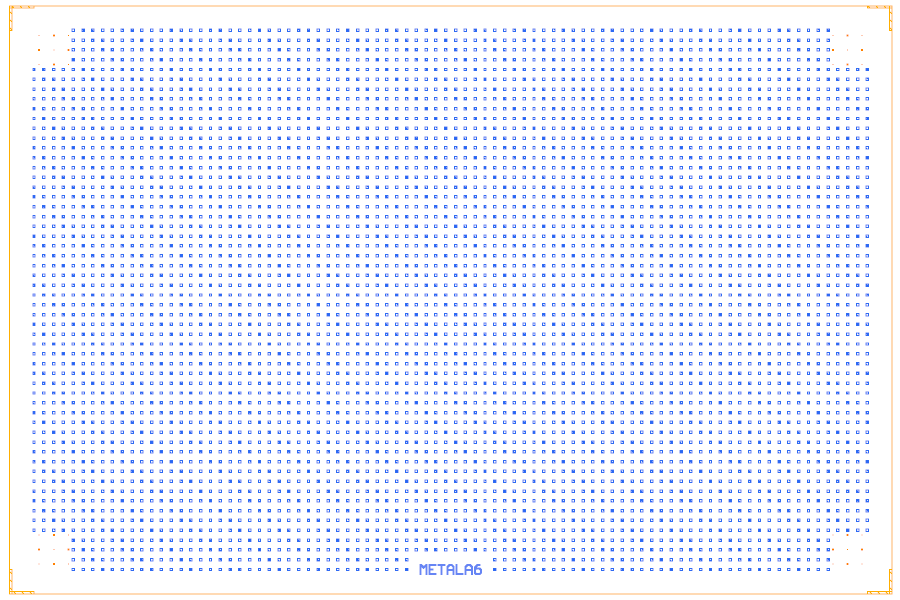

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a6_hackathon_2q_s1_die.png')

In [5]:
d = Designer("a6_hackathon_2q", box=(0, 0, 9000, 6000), chip={"name_chip": "MetalA6", "cheese": metal_cheese_rule(buffer=50)},
             live=LIVE)
X0, Y0 = 4500, 3000                              # Metal's 9 × 6 mm DesignPlanar chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
R = 99                                           # Metal fillet
layout_step(d, OUT / "a6_hackathon_2q_s1_die.png", size=(900, 600), width=450)

## Design 2 · Bond pads: the PDK pad rule

The tutorial puts its readout launchpads at x = ±3.5 mm (740 µm from the east / west edges) and its charge-line
launchpads at y = ∓2.5 mm (240 µm from the south / north edges). In the Quantcore PDK the outer edge of every bond
pad's etch sits **`frame.pad_edge` = 100 µm from the die edge**, whatever the source did: `edge="e"` / `"w"` /
`"s"` / `"n"` slides each pad perpendicular to that edge until it is there; its position along the edge is kept, so
the lines that leave a pad along its axis only get longer. The table measures it on the built layout; the picture zooms on Q1's charge-line pad at the south edge.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| Launch_Q1_Read | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| Launch_Q2_Read | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| Launch_Q1_CL | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| Launch_Q2_CL | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |

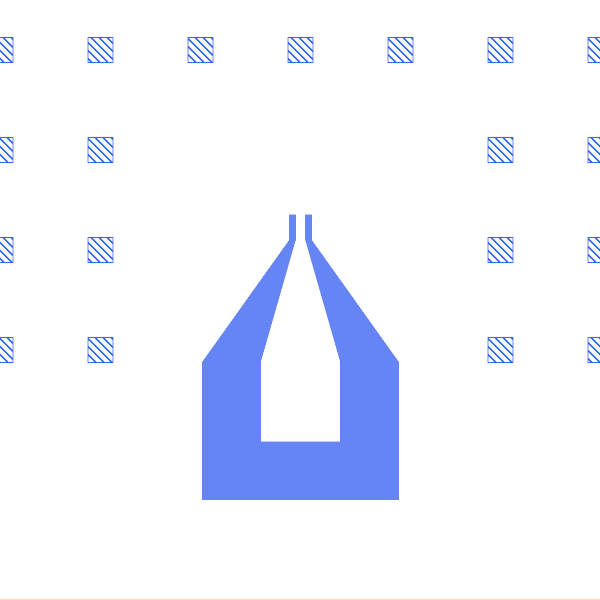

**On the chip so far:** 4 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `Launch_Q1_Read`, `Launch_Q2_Read`, `Launch_Q1_CL`, `Launch_Q2_CL`.

WindowsPath('examples/designs/metal/a6_hackathon_2q_s2_pads.png')

In [6]:
with d.batch():
    l1r = d.add("Launch_Q1_Read", "metal:LaunchpadWirebond", at=P(3500, 0), rot=180, edge="e")
    l2r = d.add("Launch_Q2_Read", "metal:LaunchpadWirebond", at=P(-3500, 0), rot=0, edge="w")
    l1c = d.add("Launch_Q1_CL", "metal:LaunchpadWirebond", at=P(1350, -2500), rot=90, edge="s")
    l2c = d.add("Launch_Q2_CL", "metal:LaunchpadWirebond", at=P(-1350, 2500), rot=-90, edge="n")
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "Launch_Q1_CL.tie")
layout_step(d, OUT / "a6_hackathon_2q_s2_pads.png", box=(px - 300, 0, px + 300, 600), size=(600, 600), width=300)

## Design 3 · Readout: the series capacitors and their pad lines

The readout line needs no qubit, so it comes first. `metal:Cap3Interdigital` (3 fingers, 40 µm) is the series capacitor between each readout and its
pad line: the readout is a λ/2 between the qubit's pad and the capacitor. The capacitors sit
2 mm out from the chip centre on either side (Q2's is the point mirror of Q1's), rotated ±90°.

**Pad lines:** plain `cpw` routes from each readout launchpad to the outer pin `b` of its capacitor (`TL_Q1`,
`TL_Q2`), one elbow each; each leaves its pad along the pad axis, so moving the pad to the edge only lengthens it.
Q2's path is the point mirror of Q1's through the chip centre (`M`), as in the source.

Cap_Q1 ports: ['a', 'b']


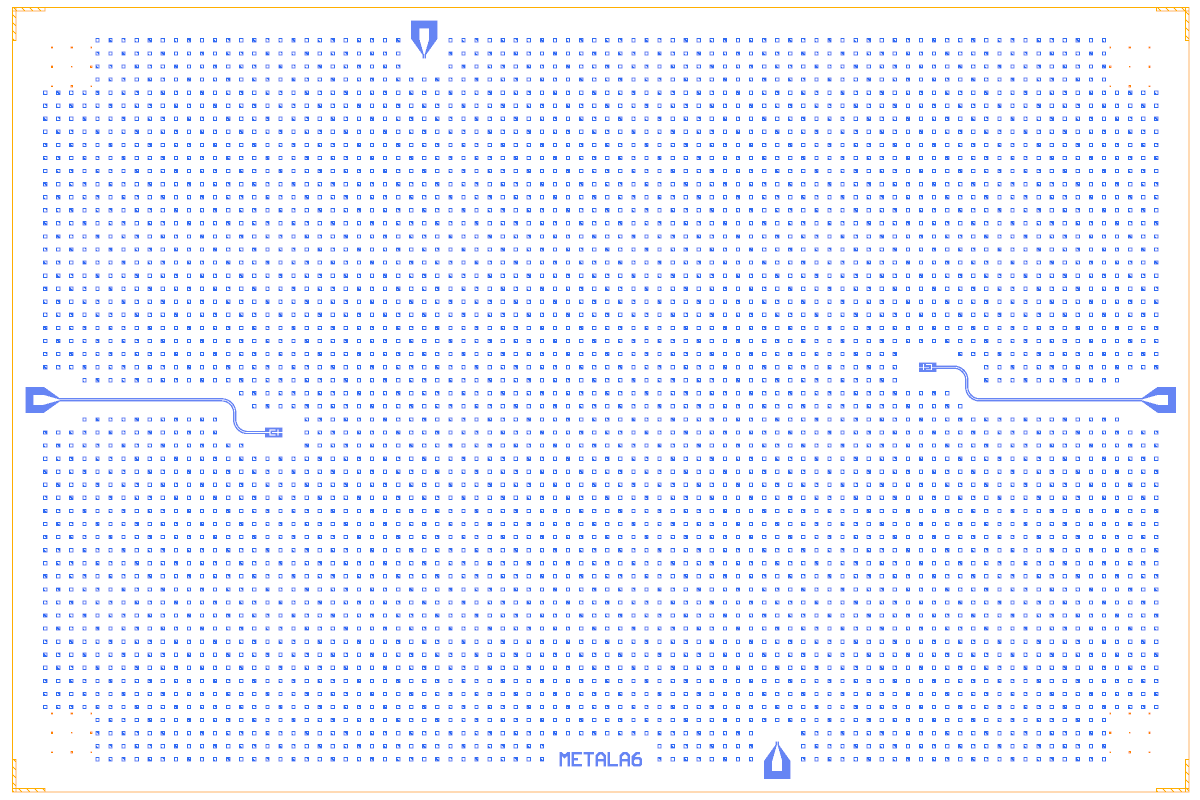

**On the chip so far:** 4 pads · 0 qubits · 2 other components · 2 routes · 0 declared couplings. **This step added** 2 component(s) `Cap_Q1`, `Cap_Q2` and 2 route(s) `TL_Q1`, `TL_Q2`.

WindowsPath('examples/designs/metal/a6_hackathon_2q_s3_readout_line.png')

In [7]:
with d.batch():
    c1 = d.add("Cap_Q1", "metal:Cap3Interdigital", at=P(2500, 250), rot=90, finger_length=40)
    c2 = d.add("Cap_Q2", "metal:Cap3Interdigital", at=P(-2500, -250), rot=-90, finger_length=40)
    M = lambda pts: [(2 * X0 - x, 2 * Y0 - y) for x, y in pts]   # point mirror through the chip centre
    d.route("TL_Q1", l1r.tie, c1.b, r=R, nodes=[(7300, 3000), (7300, 3250)])
    d.route("TL_Q2", l2r.tie, c2.b, r=R, nodes=M([(7300, 3000), (7300, 3250)]))
print("Cap_Q1 ports:", sorted(c1.ports))
layout_step(d, OUT / "a6_hackathon_2q_s3_readout_line.png", size=(1200, 800), width=480)

## Design 4 · Qubit placement: two charge-line pockets

**The qubits.** `metal:TransmonPocketCL` is Metal's pocket transmon with a charge-line pin (`Charge_Line`), drawn by
the wrapper with the tutorial's options: two 425 µm pads in a 650 µm pocket, a `readout` pad at the upper right and
a `bus` pad at the lower left. Q2 is the same cell rotated 180°.

**The junctions.** The source detunes the qubits with `hfss_inductance` 14 / 12 nH (no target frequency). The
rebuild keeps that 14 : 12 ratio round the PDK nominal L_J (6.73 nH, R_n 45 kΩ): `trilayer_junction(..., lj_nH=)`
sizes a Quantcore trilayer junction for each (Q1 7.25 nH, R_n 48.9 kΩ; Q2 6.22 nH, R_n 41.7 kΩ: both in the
40–50 kΩ window) and returns the drawn junction's L_J and C_J for the LOM and the FEM junction port (`junction=`).

The qubits sit 0.7 mm either side of the chip centre, 1.4 mm apart, facing each other with their `bus` pads. The
second picture zooms on the pair.

Q1 {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 7.252430769230769}} {'Lj_nH': 7.32, 'Cj_fF': 13.8} 
Q2 {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 6.216369230769231}} {'Lj_nH': 6.2356, 'Cj_fF': 16.2}


Q1 ports: ['Charge_Line', 'bus', 'readout', 'squid_a', 'squid_b']


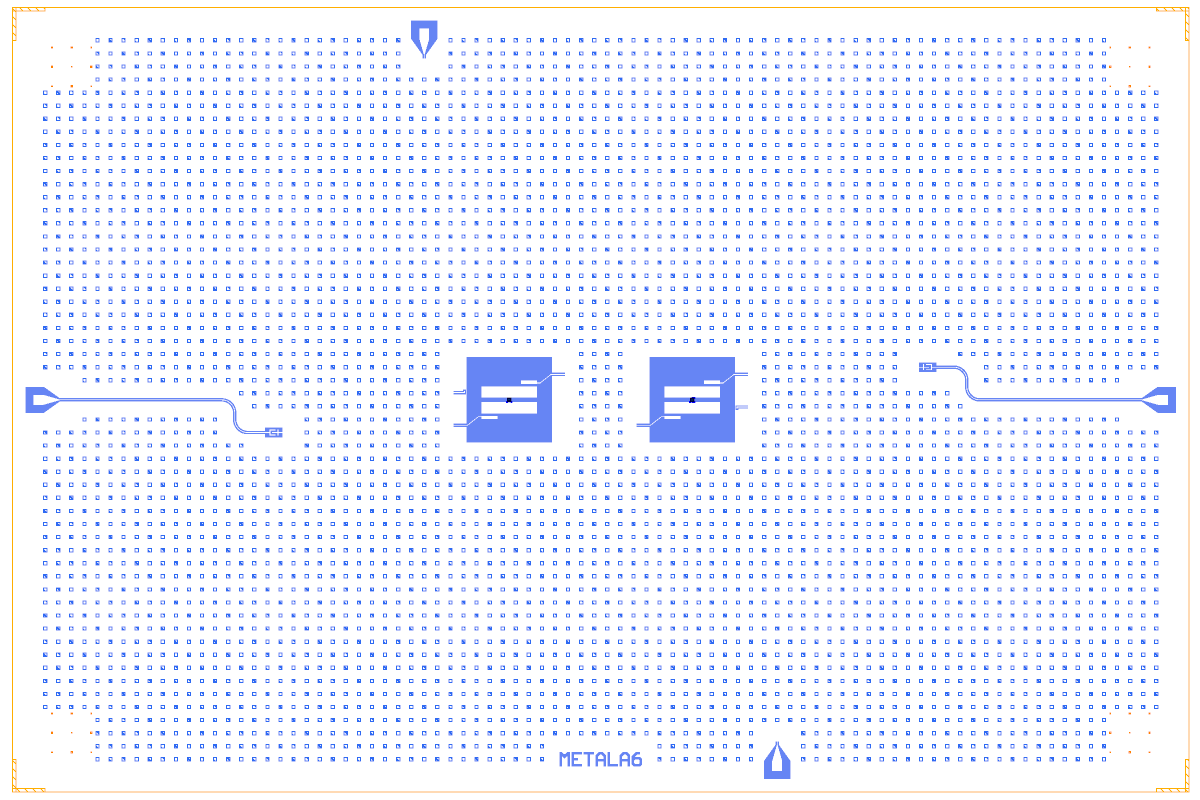

**On the chip so far:** 4 pads · 2 qubits · 2 other components · 2 routes · 0 declared couplings. **This step added** 2 component(s) `Q1`, `Q2`.

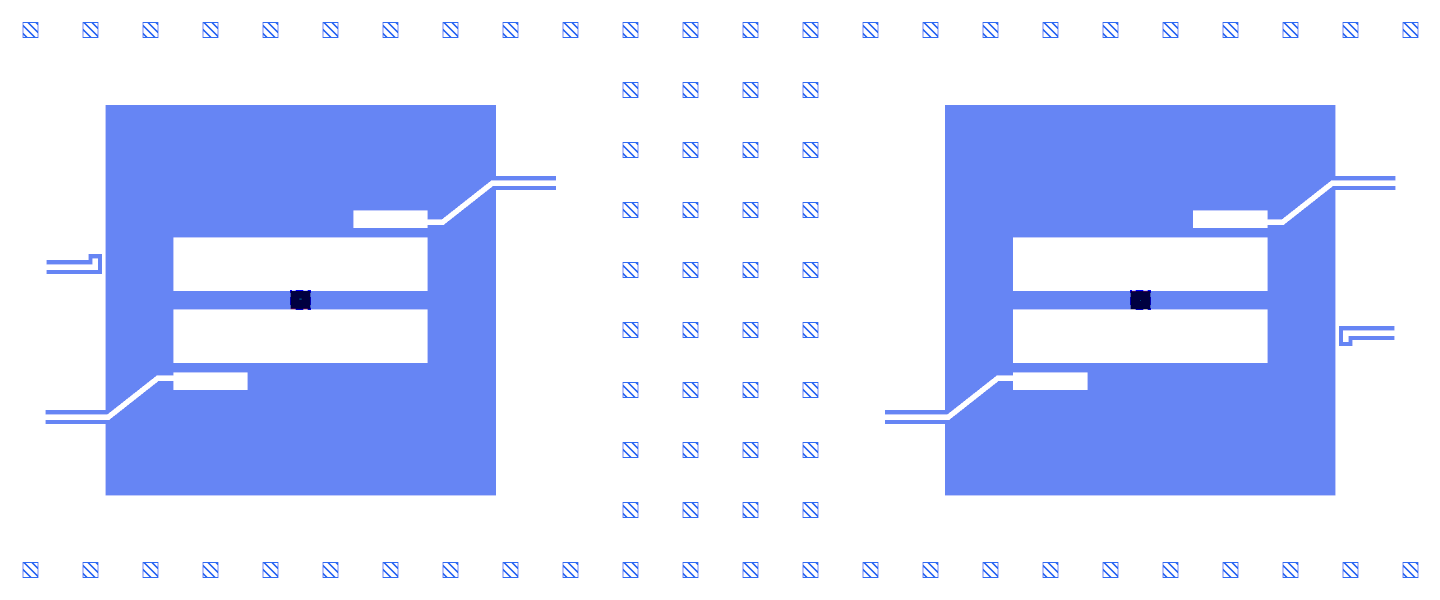

WindowsPath('examples/designs/metal/a6_hackathon_2q_step_parts.png')

In [8]:
# Quantcore trilayer junctions on the PDK rule (Nb Δ 1.4 meV). The source detunes Q1 / Q2 with hfss_inductance
# 14 / 12 nH; the rebuild keeps that ratio around the PDK nominal L_J 6.73 nH (R_n 45 kΩ): 7.25 / 6.22 nH,
# R_n 48.9 / 41.7 kΩ, both in the 40–50 kΩ window
LJ_PDK = trilayer_junction("metal:TransmonPocketCL")[1]["Lj_nH"]
JJP_Q1, JJ_Q1 = trilayer_junction("metal:TransmonPocketCL", lj_nH=LJ_PDK * 14 / 13)
JJP_Q2, JJ_Q2 = trilayer_junction("metal:TransmonPocketCL", lj_nH=LJ_PDK * 12 / 13)
print("Q1", JJP_Q1, JJ_Q1, "\nQ2", JJP_Q2, JJ_Q2)
with d.batch():
    pocket = dict(pad_width=425, pocket_height=650, cl_pocket_edge=180,
                  connection_pads={"readout": {"loc_W": 1, "loc_H": 1}, "bus": {"loc_W": -1, "loc_H": -1}})
    q1 = d.add("Q1", "metal:TransmonPocketCL", at=P(700, 0), junction=JJ_Q1, **JJP_Q1, **pocket)
    q2 = d.add("Q2", "metal:TransmonPocketCL", at=P(-700, 0), rot=180, junction=JJ_Q2, **JJP_Q2, **pocket)
print("Q1 ports:", sorted(q1.ports))
layout_step(d, OUT / "a6_hackathon_2q_s4_qubits.png", size=(1200, 800), width=480)
snap(d, OUT / "a6_hackathon_2q_step_parts.png", box=(3300, 2500, 5700, 3500), size=(1440, 600), width=640)

## Design 5 · Readout: the two λ/2 readout resonators

`meander=5000` / `6000` make fixed-length λ/2 lines from each qubit's `readout` pad to the inner pin `a` of its series
capacitor (`Readout_Q1`, `Readout_Q2`). The waypoints run them as a U through the free half of the chip above Q1
(below Q2), and the router puts the length the waypoint path leaves over into a small KQC `Meander` on the longest
free straight (turn radius 99 µm, Metal's fillet): Metal draws two tall lobes between the qubit and its capacitor,
where a symmetric qcc meander would cross the charge line. Q2's path is the point mirror of Q1's.

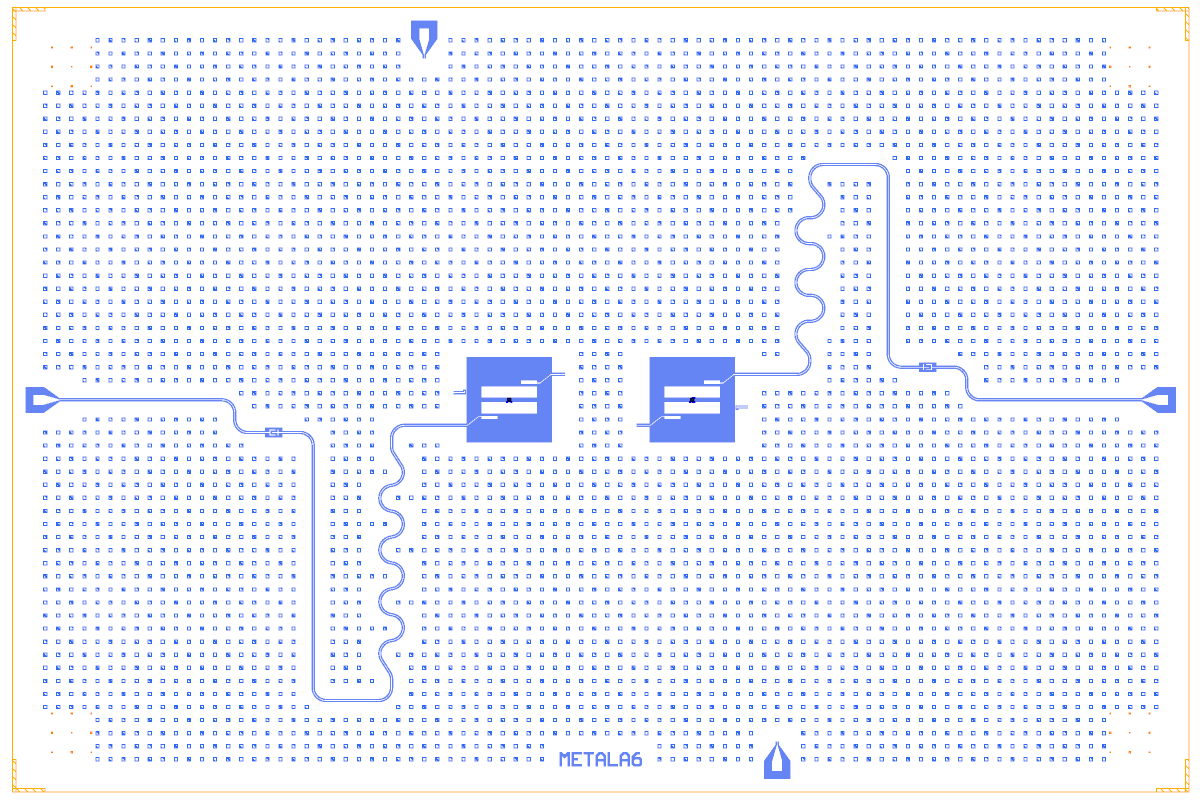

**On the chip so far:** 4 pads · 2 qubits · 2 other components · 4 routes · 0 declared couplings. **This step added** 2 route(s) `Readout_Q1`, `Readout_Q2`.

WindowsPath('examples/designs/metal/a6_hackathon_2q_s5_readouts.png')

In [9]:
with d.batch():
    # λ/2 readouts (pad → 3-finger series cap); Q2's path is the point mirror of Q1's through the chip centre
    d.route("Readout_Q1", q1.readout, c1.a, meander=5000, r=R, nodes=[(6100, 3195), (6100, 4800), (6700, 4800), (6700, 3250)])
    d.route("Readout_Q2", q2.readout, c2.a, meander=6000, r=R, nodes=M([(6100, 3195), (6100, 5300), (6700, 5300), (6700, 3250)]))
layout_step(d, OUT / "a6_hackathon_2q_s5_readouts.png", size=(1200, 800), width=480)

## Design 6 · Coupling: the direct coupling line

`Bus_Q1_Q2` joins the two `bus` pads directly through two waypoints (a Z across the 1.4 mm gap): a short,
non-resonant line, so the qubits couple capacitively through it, with no bus resonator in between.

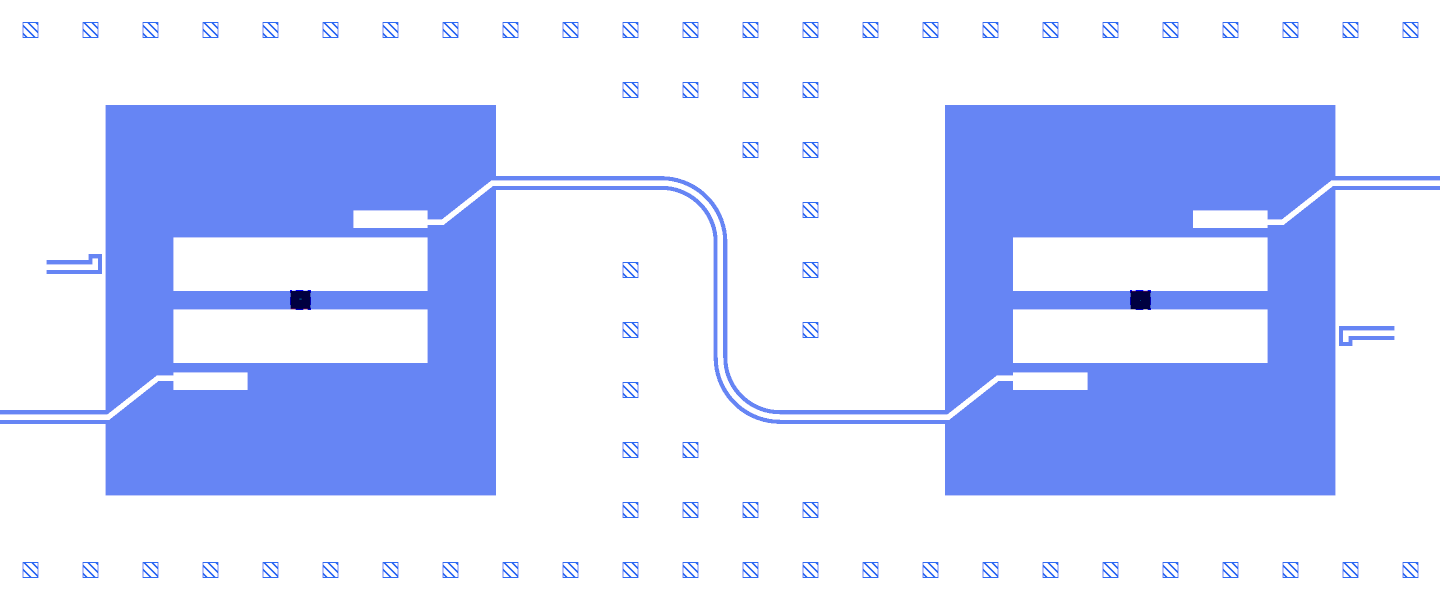

**On the chip so far:** 4 pads · 2 qubits · 2 other components · 5 routes · 0 declared couplings. **This step added** 1 route(s) `Bus_Q1_Q2`.

WindowsPath('examples/designs/metal/a6_hackathon_2q_s6_coupling.png')

In [10]:
with d.batch():
    # the direct (non-resonant) coupling line between the two bus pads
    d.route("Bus_Q1_Q2", q1.bus, q2.bus, r=R, nodes=[(4500, 2805), (4500, 3195)])
layout_step(d, OUT / "a6_hackathon_2q_s6_coupling.png", box=(3300, 2500, 5700, 3500), size=(1440, 600), width=640)

## Design 7 · Routing: the two charge lines

Plain `cpw` routes from each charge-line launchpad (south for Q1, north for Q2) into the qubit's `Charge_Line` pin
(`TL_Q1_CL`, `TL_Q2_CL`), one elbow each; they leave their pads along the pad axis, so the pad move to the edge only
lengthens them.

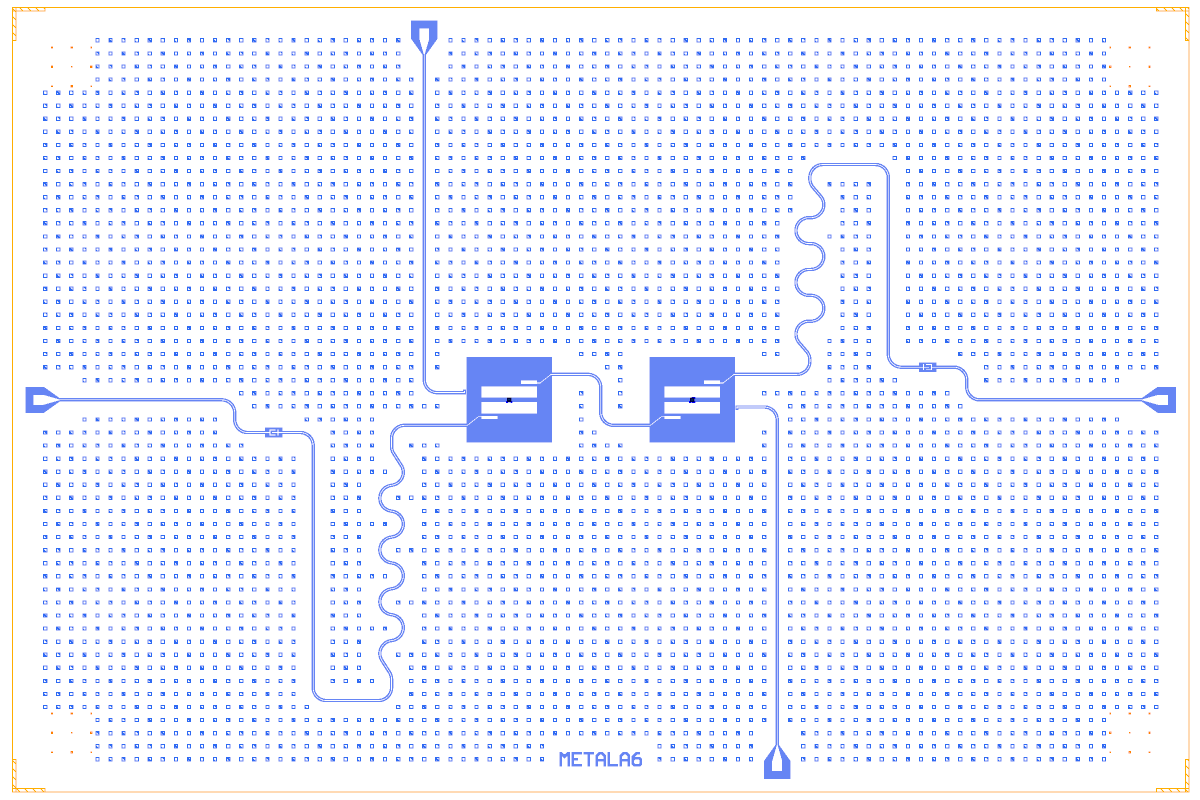

**On the chip so far:** 4 pads · 2 qubits · 2 other components · 7 routes · 0 declared couplings. **This step added** 2 route(s) `TL_Q1_CL`, `TL_Q2_CL`.

WindowsPath('examples/designs/metal/a6_hackathon_2q_s7_charge_lines.png')

In [11]:
with d.batch():
    # charge lines into the TransmonPocketCL Charge_Line pins
    d.route("TL_Q1_CL", l1c.tie, q1.Charge_Line, r=R, nodes=[(5850, 2945)])
    d.route("TL_Q2_CL", l2c.tie, q2.Charge_Line, r=R, nodes=[(3150, 3055)])
layout_step(d, OUT / "a6_hackathon_2q_s7_charge_lines.png", size=(1200, 800), width=480)

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups** say what a FEM job cuts out of the chip: the two qubits with the coupling line (`Q1_Q2`, Q3D C-matrix:
the tutorial's own Q3D + LOM step), and each qubit with its readout and capacitor (`Q1_read`, `Q2_read`, Q3D and
eigenmode). The margins make each box cut every other line once.

**Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). With pads on all four edges and the point-symmetric layout, nothing should move.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*. The
file keeps the previous key order (the capacitors and pad lines were added before the qubits here), so `git diff`
stays empty.

content shifted by (0.0, 0.0) µm


**Same design as before:** `examples/designs/metal/a6_hackathon_2q.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer a6_hackathon_2q: 8 instances, 7 routes, live=False> → examples\designs\metal\a6_hackathon_2q.json
route lengths (µm): {'TL_Q1': 1715, 'TL_Q2': 1715, 'Readout_Q1': 5000, 'Readout_Q2': 6000, 'Bus_Q1_Q2': 855, 'TL_Q1_CL': 2751, 'TL_Q2_CL': 2751}


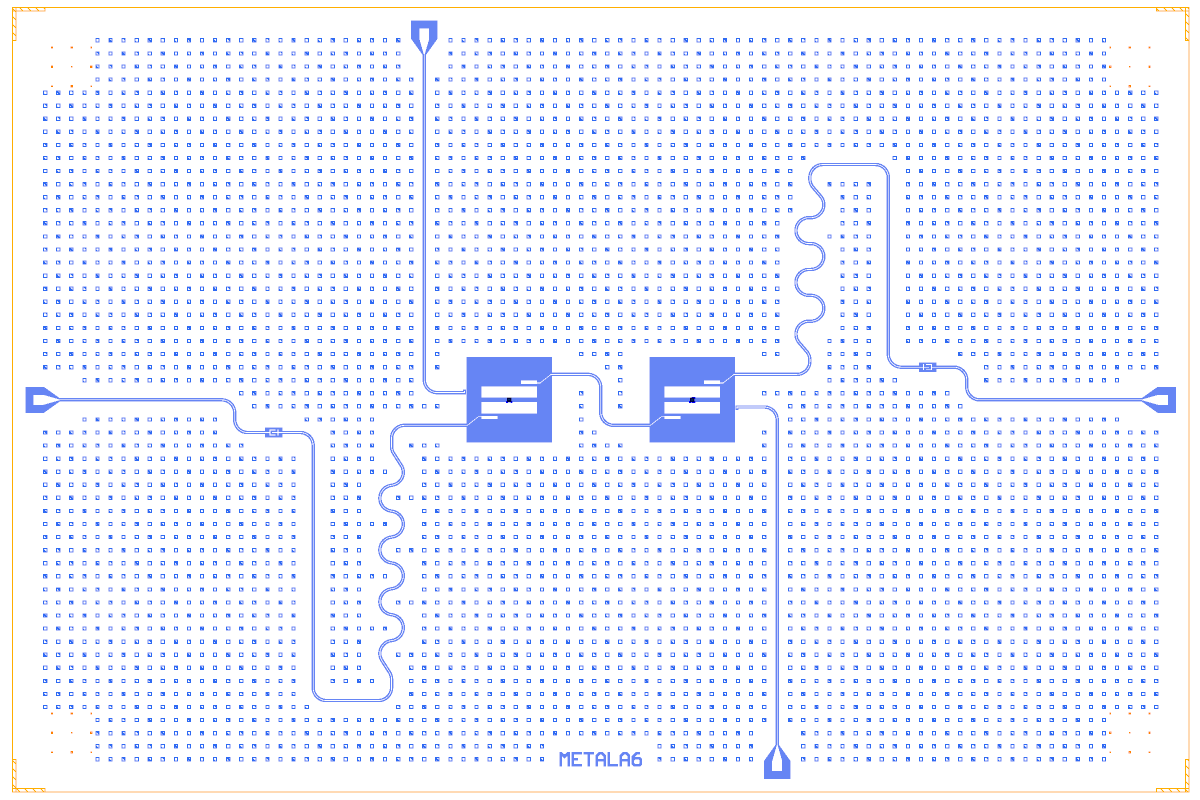

**On the chip so far:** 4 pads · 2 qubits · 2 other components · 7 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a6_hackathon_2q_step_routes.png')

In [12]:
# FEM boxes: margins chosen so that each box cuts every other line once
d.sim_group("Q1_Q2", ["Q1", "Q2", "Bus_Q1_Q2"], margin_um=150, analyses=["q3d_cmatrix"])
for k in (1, 2):
    d.sim_group(f"Q{k}_read", [f"Q{k}", f"Readout_Q{k}", f"Cap_Q{k}"], margin_um=150, analyses=["q3d_cmatrix", "eigenmode_epr"])
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN, same = save_design(d, OUT / "a6_hackathon_2q.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "a6_hackathon_2q_step_routes.png", size=(1200, 800), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**, four `dangling_port` warnings (`Q1`/`Q2` `squid_a` / `squid_b`, the junctions'
attachment points: the qubit cell draws the junction itself, nothing is routed there) and **no PDK design
warnings**: the pads are at 100 µm, both junctions are inside the 40–50 kΩ R_n window, and the source states no
target frequency.

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: a `TransmonPocketCL` gives two floating pad nodes with the junction
between them, a node per connection pad, and the `Charge_Line` as a drive port (a small capacitance to the near pad).
The two `bus` pads are joined by the short coupling line (one node, no resonance in band); each readout between a
pad and a series capacitor to a 50 Ω launchpad port is a λ/2 `TLres`. The port map shows where Q1's ports landed.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "Cap_Q1."))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Each qubit with its readout, capacitor, pad line and launchpad (both charge lines are 50 Ω loads); then the two
qubits with the coupling line (QuCat normal modes and the static ZZ from QuTiP). With the PDK-sized junctions (numbers from the v1 run) the
qubits sit near 7.0 / 7.4 GHz (the source's 14 / 12 nH gave 5.42 / 5.89 GHz); the tutorial states no targets, so
the comparison is with the PDK band (4–8 GHz) and the source's detuning, which is kept.

In [ ]:
read = {f"Q{k}+read": [f"Q{k}", f"Readout_Q{k}", f"Cap_Q{k}", f"TL_Q{k}", f"Launch_Q{k}_Read", f"TL_Q{k}_CL",
                       f"Launch_Q{k}_CL"] for k in (1, 2)}
results = simulate_groups(d, read)
display(Markdown(groups_md(results)))
pair = simulate_groups(d, {"Q1+Q2+bus": ["Q1", "Q2", "Bus_Q1_Q2"]})
display(Markdown("**Q1 + Q2 + coupling line, QuCat normal modes:**\n\n" + modes_md(pair["Q1+Q2+bus"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(pair)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each readout. Here (from the
v1 run) both λ/2 readouts sit above their qubits (11.7 and 9.9 GHz against 6.96 and 7.43 GHz), and the coupling line
adds no mode of its own to the `Q1+Q2+bus` group.

In [ ]:
plot_lom({**results, **pair}, OUT / "a6_hackathon_2q_lom.png", title="a6: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here Q1's junction, from the detuned 7.25 nH back to the PDK nominal 6.73 nH (R_n
45 kΩ) — rebuild, re-run the LOM of Q1 with its readout and compare. A smaller L_J raises f_q (f_q ∝ 1/√(L_J C_Σ)),
which shrinks the qubit–readout detuning and the dispersive shift moves with it.

In [ ]:
d2 = design_copy(DESIGN)
JJP_NOM, JJ_NOM = trilayer_junction("metal:TransmonPocketCL", lj_nH=LJ_PDK)
d2["Q1"].set(junction=JJ_NOM, **JJP_NOM)         # 7.25 → 6.73 nH (and the drawn finger with it)
after = simulate_groups(d2, {"Q1+read": read["Q1+read"]})
display(Markdown(params_delta_md({"Q1+read": results["Q1+read"]}, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

A **Q3D C-matrix** job for the two qubits with the coupling line (the tutorial's own Q3D + LOM step: it gives
the island capacitances and the qubit–qubit coupling C), and, per qubit, a C-matrix and an **eigenmode / EPR** job
with its readout and capacitor (lines leaving the box end in 50 Ω, so the mode Q gives κ).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group
jobs_eig = export_sims(DESIGN, ["Q1_read", "Q2_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each component group: `Q1_read` and `Q2_read` (the qubit's two pads, its connection pads, the
readout stub, the capacitor and the lines the box cuts, as named nets) and `Q1_Q2` (the two qubits with the coupling
line: the island capacitances and the qubit–qubit coupling C). Each net is named after its LOM node, so the matrix
goes straight into the circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results,
else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same `Q1_read` / `Q2_read` boxes in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet, every line the box
cuts (the pad line beyond the capacitor, the coupling line, the charge line) ends in 50 Ω, so each mode's Q gives κ.
pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the junction's energy participation
p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh**
itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim
group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes), the
adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it. Here for `Q1_read`.

This chip's readouts end on a series capacitor to their pad line, not on a feedline: the job's ports are the lines the
box cuts, so the S21 notch fit (made for hangers) may find no notch; then κ comes from the eigenmode Q (Results 2).

In [ ]:
f_r1 = results["Q1+read"].params.get("Readout_Q1.f_GHz")    # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1_read", jobs_eig["Q1_read"][0], keep_eig["Q1_read"], f_guess=f_r1)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1_read"]:
    display(Markdown(driven_md(keep_drv["Q1_read"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {}
for k in (1, 2):
    lom_f[f"Q{k}"] = results[f"Q{k}+read"].params.get(f"Q{k}.f_q_GHz")
    lom_f[f"Readout_Q{k}"] = results[f"Q{k}+read"].params.get(f"Readout_Q{k}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "a6_hackathon_2q_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its notch (if any).

In [ ]:
fem_values = {}
for k in (1, 2):
    keep = keep_eig.get(f"Q{k}_read")
    if keep:
        fem_values[f"Q{k}"] = epr_values(keep, {f"Q{k}": f"Readout_Q{k}"}, {f"Readout_Q{k}": lom_f[f"Readout_Q{k}"]})
if keep_drv["Q1_read"]:
    fem_values.setdefault("Q1", {}).update({f"driven {k}": v for k, v in
                                            driven_values(keep_drv["Q1_read"], "Readout_Q1", f_r1).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for vals in fem_values.values() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of Q1 / Q2 and "
          "their readouts from pyEPR, and the S21 notch of the Q1 readout (if any).")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
for k in (1, 2):
    g, est = f"Q{k}+read", results[f"Q{k}+read"].params
    keys = [f"Q{k}.f_q_GHz", f"Q{k}.alpha_MHz", f"Readout_Q{k}.f_GHz", f"Readout_Q{k}.chi_MHz",
            f"Readout_Q{k}.kappa_MHz"]
    if keep_q3d.get(f"Q{k}_read"):
        on_fem = simulate(fill(d.lom(select=read[g]).model, DESIGN, keep_q3d[f"Q{k}_read"]), max_modes=2).params
        rows += [(key, est.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
    for key in keys:
        if key in fem_values.get(f"Q{k}", {}):
            rows.append((key, est.get(key), fem_values[f"Q{k}"][key], "eigenmode + pyEPR"))
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The tutorial states no target frequency, only the 14 : 12 detuning. This notebook sets one target as an exercise:
**Q2 at 7.2 GHz**, ≈ 0.23 GHz below where the LOM puts it (from the v1 run: 7.435 GHz), nearer the PDK nominal
junction. It is reachable inside the PDK junction window: by the transmon formula Q2's L_J goes from 6.24 nH (drawn)
to ≈ 6.6 nH, R_n ≈ 44 kΩ (`pdk_lj_bounds` keeps the feedback within 40–50 kΩ). Q1 and the readouts are not targeted.

The targets go on a copy (`target_copy` → `build/a6_hackathon_2q_target.json`), so the design file keeps its own
(none). `loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — on the Q3D values where a solve was kept — and picks one value per quantity (the consensus).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the target inside its tolerance
(f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision changes the LOM's
L_J (`Q2.junction.Lj_nH`); this chip draws its junctions from `junction_params.lj_nH` (Design 4), so to draw the new
one set both with `trilayer_junction("metal:TransmonPocketCL", lj_nH=...)`.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q2": {"f_q_GHz": 7.2}}               # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/a6_hackathon_2q/revisions/`). Without
`RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` each revision's `Q2_read` Q3D job is exported and
solved first (`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each
iteration's value against the target and the knob it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = export_sims(rev, ["Q2_read"], root=f"build/jobs/rev{k}")
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "a6_hackathon_2q_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** The A.6 notebook exports its GDS with Metal's `QGDSRenderer`, whose cheese is on by default (`cheese.view_in_file = {main: {1: True}}`: 25 µm squares every 100 µm, `edge_nocheese` 200 µm), and sets `no_cheese.buffer = 50um`. So the original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule as its `cheese` parameter (Design 1: `metal_cheese_rule(buffer=50)` = `{size, gap, rows, clearance, edge}`), so the build draws it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0 keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (`cheese source: build`, no PDK band added).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip (compare the tutorial's screenshot); the two qubits with the coupling line and the charge-line ends;
Q1's trilayer junction; the `Cap_Q1` interdigital capacitor; the **fab mask** round Q1 (1/0 etch with the
original's Metal cheese, the 3/0 keep-out, the junction layers); and the die frame's south-west corner (dicing L on
1000/0, alignment grid on 1001/0). Positions are read from the design (after the centring shift).

In [ ]:
Q1X, Q1Y = d.data["instances"]["Q1"]["place"]["at"]
Q2X, Q2Y = d.data["instances"]["Q2"]["place"]["at"]
CX, CY = d.data["instances"]["Cap_Q1"]["place"]["at"]
mx, my = (Q1X + Q2X) / 2, (Q1Y + Q2Y) / 2
show_snapshot(d, OUT / "a6_hackathon_2q.png", size=(1500, 1000))
show_snapshot(d, OUT / "a6_hackathon_2q_qubits.png", box=(mx - 1200, my - 500, mx + 1200, my + 500), size=(1440, 600),
              width=640)
show_snapshot(d, OUT / "a6_hackathon_2q_jj.png", box=(Q1X - 40, Q1Y - 40, Q1X + 40, Q1Y + 40), width=300)
show_snapshot(d, OUT / "a6_hackathon_2q_cap.png", box=(CX - 150, CY - 100, CX + 150, CY + 100), size=(900, 600), width=360)
snap_file(Path("build") / "a6_hackathon_2q_fab.oas", OUT / "a6_hackathon_2q_cheese.png",
          box=(Q1X - 600, Q1Y - 500, Q1X + 600, Q1Y + 500), size=(1200, 1000), width=420)
show_snapshot(d, OUT / "a6_hackathon_2q_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, the route end pins, the 5.0 / 6.0 mm readouts, the direct coupling line, the source's 14 : 12 junction detuning |
| PDK changes | QCT frame on the source's 9 × 6 mm box; sapphire stack; the four launchpads 100 µm from the edges (were 740 µm east / west, 240 µm south / north); trilayer junctions 7.25 / 6.22 nH (R_n 48.9 / 41.7 kΩ); cheese = the original's Metal cheese, drawn by the build; content centred (shift printed in Design 8) |
| differs | the readout meanders' shape (qcc router); from the v1 run: f_q 6.96 / 7.43 GHz, readouts 11.70 / 9.87 GHz (χ −1.6 / −3.4 MHz), Q1–Q2 ZZ ≈ −6.9 MHz with the PDK junctions (the source's 14 / 12 nH gave 5.42 / 5.89 GHz) |
| PDK design warnings | none |
| layout | built in eight segments (die, pads, capacitors with their pad lines, qubits, readouts, coupling line, charge lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (Q2 7.2 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`); the drawn junction follows only through `trilayer_junction` (see Results 4) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |